# Credit Scoring — Exploratory Data Analysis

## Project Goal

Analyze credit data to identify patterns associated
with loan defaults and prepare data for machine learning.

## 1. Import Libraries

We import Pandas for data manipulation and Matplotlib
for data visualization.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load Dataset

We load the credit scoring dataset from a CSV file
using Pandas.

The dataset contains borrower characteristics,
loan information, and the target variable `default`.

In [6]:
df = pd.read_csv("../Dataset/lending_club_clean.csv")

df.head()

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,default
0,3200,36.0,7.35,99.32,0,3,10.0,5,41000.0,1,1,2.69,0.0,2.0,13.0,1.0,1989,11.8,48.0,0
1,8000,36.0,13.18,270.25,2,12,6.0,1,80000.0,1,2,9.54,0.0,1.0,4.0,0.0,4279,99.5,4.0,1
2,25000,36.0,8.90,793.84,0,4,10.0,1,150000.0,2,1,5.18,1.0,0.0,12.0,0.0,25863,67.0,27.0,0
3,6000,36.0,9.17,191.28,1,6,8.0,1,51000.0,1,9,16.24,1.0,0.0,9.0,0.0,8036,94.5,18.0,0
4,35000,36.0,14.65,1207.30,2,14,3.0,1,200000.0,2,2,29.97,0.0,1.0,13.0,0.0,22936,53.0,34.0,0


## 3. Dataset Overview

We examine the dimensions of the dataset to determine
the number of observations and features.

The `shape` attribute returns the number of rows
and columns.

In [7]:
df.shape

(150000, 20)

## 4. Data Types

In this section, we examine the structure of the dataset.

The `info()` method provides information about:
- Column names
- Data types
- Number of non-null values
- Memory usage

This helps us identify categorical and numerical features
and detect potential missing values.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 20 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   loan_amnt            150000 non-null  int64  
 1   term                 150000 non-null  float64
 2   int_rate             150000 non-null  float64
 3   installment          150000 non-null  float64
 4   grade                150000 non-null  int64  
 5   sub_grade            150000 non-null  int64  
 6   emp_length           141357 non-null  float64
 7   home_ownership       150000 non-null  int64  
 8   annual_inc           150000 non-null  float64
 9   verification_status  150000 non-null  int64  
 10  purpose              150000 non-null  int64  
 11  dti                  149964 non-null  float64
 12  delinq_2yrs          150000 non-null  float64
 13  inq_last_6mths       150000 non-null  float64
 14  open_acc             150000 non-null  float64
 15  pub_rec              150000 

## 5. Missing Values Analysis

Missing values can affect the quality of machine learning models.

We use `isnull()` to identify missing values
and `sum()` to calculate their number in each column.

At this stage, we only investigate missing values.
No data cleaning is performed.

In [9]:
df.isnull().sum()

loan_amnt                 0
term                      0
int_rate                  0
installment               0
grade                     0
sub_grade                 0
emp_length             8643
home_ownership            0
annual_inc                0
verification_status       0
purpose                   0
dti                      36
delinq_2yrs               0
inq_last_6mths            0
open_acc                  0
pub_rec                   0
revol_bal                 0
revol_util              101
total_acc                 0
default                   0
dtype: int64

### Findings

Missing values were detected in three features:

- `emp_length`: 8,643 missing values (5.76%)
- `dti`: 36 missing values (0.024%)
- `revol_util`: 101 missing values (0.067%)

The remaining features contain no missing values.

The largest number of missing values occurs in `emp_length`.

### Conclusion

Removing all rows with missing values could lead to
unnecessary information loss.

Missing values will be handled during the preprocessing stage.

## 6. Target Variable Distribution

The target variable is `default`.

It represents whether a borrower experienced a credit default:

- `0` — No default
- `1` — Default

We calculate the number and percentage of observations
belonging to each class.

This allows us to identify potential class imbalance.

In [10]:
print(df["default"].value_counts())

print(df["default"].value_counts(normalize=True) * 100)

default
0    119727
1     30273
Name: count, dtype: int64
default
0    79.818
1    20.182
Name: proportion, dtype: float64


### Findings

The target distribution is imbalanced:

- Class 0 (No Default): 119,727 observations (79.82%)
- Class 1 (Default): 30,273 observations (20.18%)

A model that always predicts the majority class
would achieve approximately 79.82% accuracy
on this dataset.

However, such a model would fail to identify any defaults.

### Conclusion

Accuracy alone is not sufficient for model evaluation.

Additional metrics, including Precision, Recall,
F1-score, and ROC-AUC, will be considered.

## 7. Target Distribution Visualization

We visualize the target variable using a bar chart.

The chart shows the number of borrowers in each class,
making the class imbalance easier to interpret.

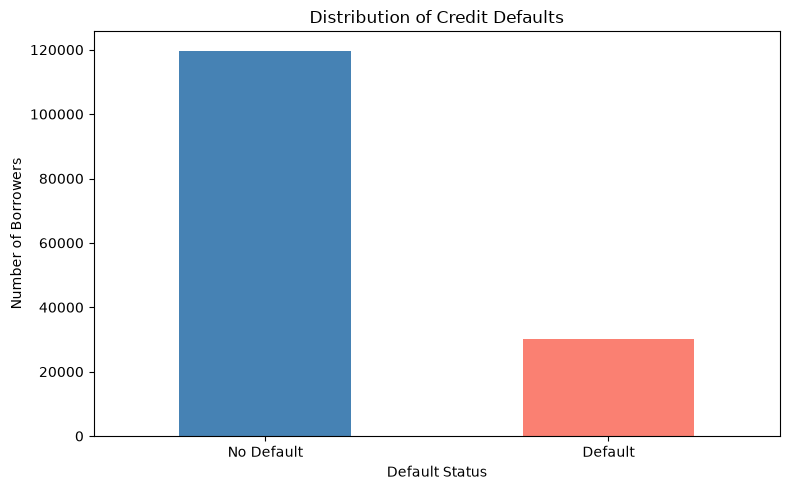

In [11]:
plt.figure(figsize=(8, 5))

df["default"].value_counts().sort_index().plot(
    kind="bar",
    color=["steelblue", "salmon"]
)

plt.title("Distribution of Credit Defaults")
plt.xlabel("Default Status")
plt.ylabel("Number of Borrowers")

plt.xticks(
    ticks=[0, 1],
    labels=["No Default", "Default"],
    rotation=0
)

plt.tight_layout()
plt.show()

## 8. Loan Amount Descriptive Statistics

We analyze the `loan_amnt` feature to understand
the distribution of loan amounts.

The `describe()` method calculates:

- Count
- Mean
- Standard deviation
- Minimum and maximum
- Quartiles (25%, 50%, 75%)

These statistics help us understand the typical loan amount,
data variability, and potential distribution asymmetry.

In [12]:
df["loan_amnt"].describe()

count    150000.000000
mean      14410.639667
std        8692.286974
min         500.000000
25%        8000.000000
50%       12000.000000
75%       20000.000000
max       40000.000000
Name: loan_amnt, dtype: float64

### Findings

- The average loan amount is approximately 14,410.64.
- The median loan amount is 12,000.
- The middle 50% of loans range from 8,000 to 20,000.
- The minimum loan amount is 500.
- The maximum loan amount is 40,000.

The mean is higher than the median, suggesting
a potentially right-skewed distribution.

Further visualization is needed to investigate
the distribution.

## 9. Loan Amount Distribution

We use a histogram to examine the distribution of loan amounts.

A histogram divides numerical values into intervals (bins)
and shows the number of observations in each interval.

This visualization helps us:
- Identify common loan amounts.
- Examine the shape of the distribution.
- Detect potential skewness.
- Identify unusual values.

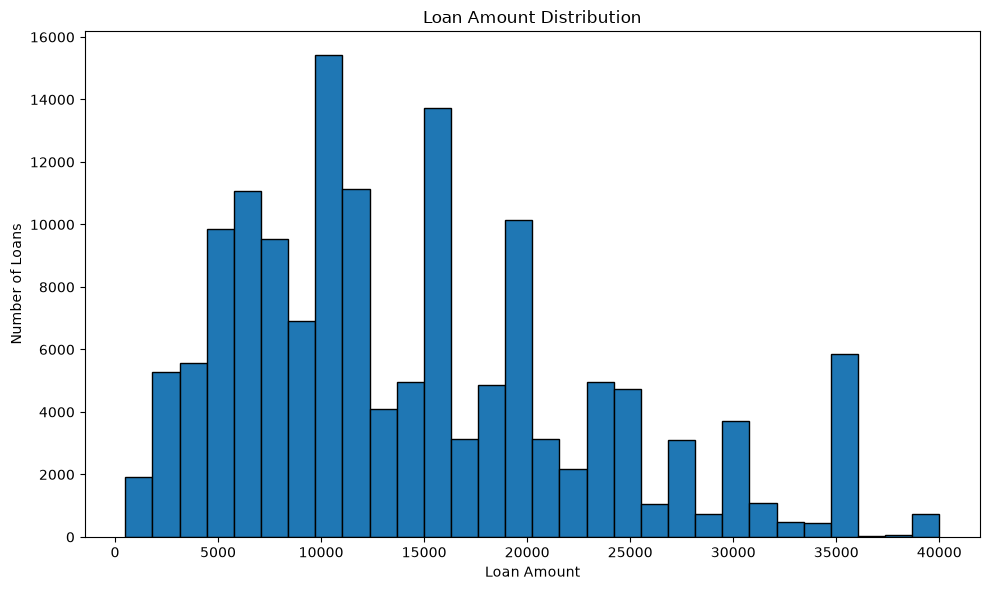

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["loan_amnt"],
    bins=30,
    edgecolor="black"
)

plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Loans")

plt.tight_layout()
plt.show()

### Findings

The histogram reveals several characteristics:

- A large proportion of loans are concentrated between
  approximately 5,000 and 20,000.
- The distribution is right-skewed.
- The mean loan amount (14,410.64) exceeds
  the median (12,000).
- Several peaks appear around common loan amounts.
- Larger loans are generally less frequent.

### Conclusion

The loan amount distribution shows positive skewness.

Further analysis is required to identify potential
outliers and evaluate their impact on the dataset.

## 10. Outlier Detection Using Boxplot

A boxplot visualizes the distribution of numerical data
using quartiles and the median.

We use the Interquartile Range (IQR) method
to identify potential outliers.

The IQR is calculated as:

**IQR = Q3 - Q1**

Potential outliers are values outside the following bounds:

- Lower bound: Q1 - 1.5 × IQR
- Upper bound: Q3 + 1.5 × IQR

Values outside these bounds are considered potential
outliers and require further investigation.

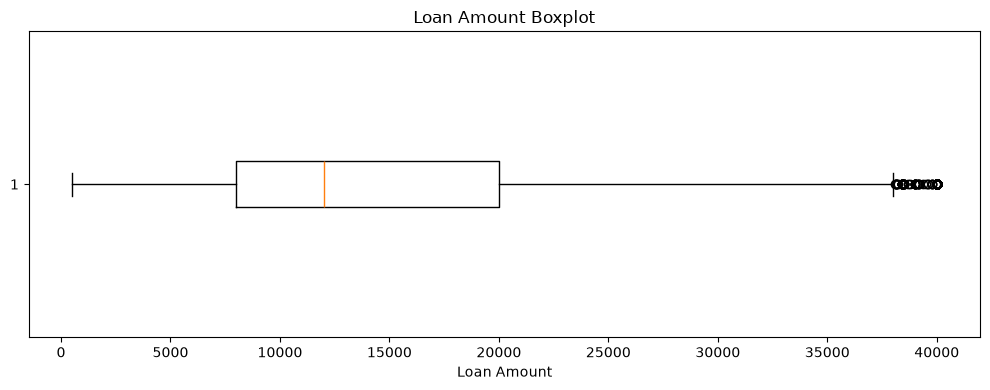

In [18]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    df["loan_amnt"],
    orientation="horizontal"
)

plt.title("Loan Amount Boxplot")
plt.xlabel("Loan Amount")

plt.tight_layout()
plt.show()

## 11. Outlier Quantification

After identifying potential outliers visually,
we calculate their exact number using the IQR method.

We define the lower and upper bounds and select
observations outside these limits.

At this stage, no observations are removed.

In [16]:
q1 = df["loan_amnt"].quantile(0.25)
q3 = df["loan_amnt"].quantile(0.75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[
    (df["loan_amnt"] < lower) |
    (df["loan_amnt"] > upper)
]

print("Lower bound:", lower)
print("Upper bound:", upper)
print("Number of outliers:", len(outliers))
print("Outlier percentage:", round(len(outliers) / len(df) * 100, 2), "%")

Lower bound: -10000.0
Upper bound: 38000.0
Number of outliers: 769
Outlier percentage: 0.51 %


### Findings

The IQR analysis produced the following results:

| Statistic | Value |
|-----------|------:|
| Q1 | 8,000 |
| Q3 | 20,000 |
| IQR | 12,000 |
| Lower bound | -10,000 |
| Upper bound | 38,000 |
| Potential outliers | 769 |
| Outlier percentage | 0.51% |

### Conclusion

Only 0.51% of loan amounts fall outside the IQR bounds.

All identified potential outliers are above
the upper boundary of 38,000.

These observations may represent legitimate
large loans rather than data errors.

Therefore, no outliers are removed at this stage.

Further investigation will be performed
before deciding whether outlier treatment is necessary.

## 12. Loan Amount vs Default

In this section, we investigate the relationship between
loan amounts and credit defaults.

**Hypothesis:** Borrowers with larger loans may have
higher default rates.

We group loans by their amounts and calculate the
average value of the target variable.

Since `default` is binary (0 or 1), its mean represents
the proportion of defaults within each group.

In [19]:
df.groupby("loan_amnt")["default"].mean().head(10)

loan_amnt
500     0.000000
1000    0.125191
1025    0.000000
1050    0.200000
1075    0.000000
1100    0.153846
1125    0.166667
1150    0.250000
1175    0.000000
1200    0.113924
Name: default, dtype: float64

### Loan Amount Grouping

To obtain more reliable default rate estimates, we group
loan amounts into intervals using `pd.cut()`.

This approach reduces the impact of individual observations
and allows us to compare default rates across loan ranges.

We calculate:
- Number of loans in each group.
- Average default rate for each group.

In [21]:
loan_default_stats["default_rate_pct"] = (
    loan_default_stats["mean"] * 100
)

loan_default_stats

,count,mean,default_rate_pct
loan_amnt,,,
"(0, 10000]",61818,0.170339,17.033874
"(10000, 20000]",55652,0.218555,21.855459
"(20000, 30000]",23624,0.227946,22.794616
"(30000, 40000]",8906,0.246463,24.646306


### Default Rate by Loan Amount

We visualize the relationship between loan amount ranges
and default rates using a bar chart.

The chart helps us compare the percentage of defaults
across different loan amount groups.

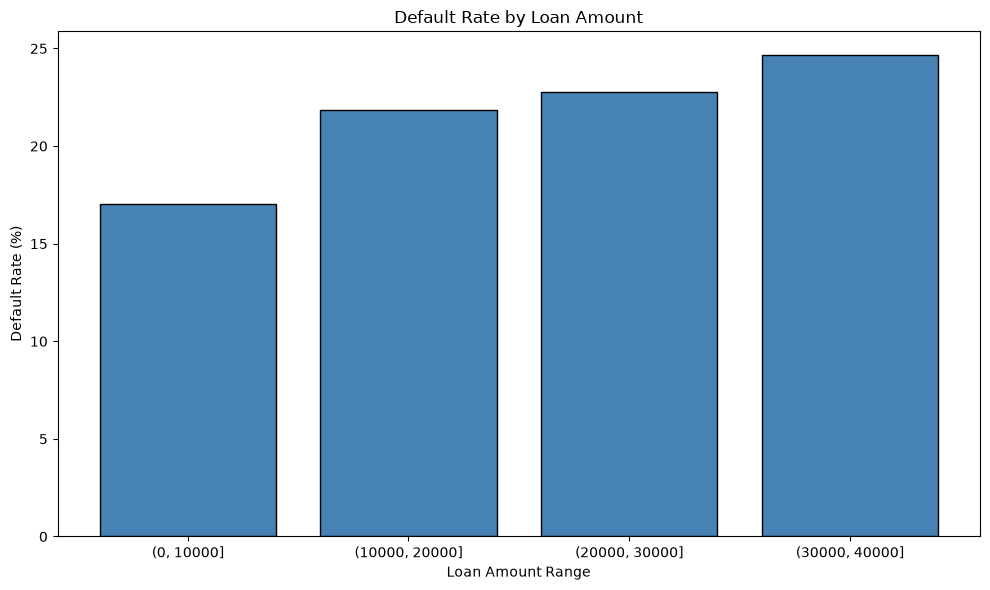

In [22]:
plt.figure(figsize=(10, 6))

plt.bar(
    loan_default_stats.index.astype(str),
    loan_default_stats["default_rate_pct"],
    color="steelblue",
    edgecolor="black"
)

plt.title("Default Rate by Loan Amount")
plt.xlabel("Loan Amount Range")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

### Findings

The analysis revealed an increasing default rate across loan amount groups.

| Loan Amount Range | Number of Loans | Default Rate |
|---|---:|---:|
| 0–10,000 | 61,818 | 17.03% |
| 10,000–20,000 | 55,652 | 21.86% |
| 20,000–30,000 | 23,624 | 22.79% |
| 30,000–40,000 | 8,906 | 24.65% |

### Key Observations

- The lowest default rate (17.03%) was observed among loans up to 10,000.
- The highest default rate (24.65%) was observed among loans between 30,000 and 40,000.
- The difference between the highest and lowest default rates is approximately 7.62 percentage points.
- Default rates increase across the analyzed loan amount ranges.

### Conclusion

The results support the hypothesis that larger loan amounts are associated with higher default rates in this dataset.

However, this relationship does not establish causation. Other borrower characteristics, such as income, credit history, and debt burden, may influence the observed pattern.

Further analysis is required to investigate these relationships.